# Parametric Drought-Index Insurance Simulator: Eastern Rwanda Maize
Data and modelling pipeline for the capstone proposal (Chapter Three).

### How this notebook maps to the ML track

| Requirement | Where |
|---|---|
| Data engineering | Sections 3–6b (satellite extraction, NISR yields, the 2024 reconstruction) and the **Data engineering summary** at the end of Section 6 |
| Data visualization | Section 7: distributions, relationships, **correlation matrix**, **yields by district**, seasonal profiles, peak-NDVI sensitivity |
| Model architecture | Section 8: model comparison and **Model architecture** (pipeline, penalty, optimisation, tuning curve) |
| Initial performance metrics | Section 8 (RMSE, MAE, predictive R² under two validation schemes) and Section 9 (**accuracy, precision, recall, F1, confusion matrix** for the payout decision) |
| Deployment option | Section 12: FastAPI backend with Swagger UI and the Next.js dashboard |

## 1. Setup
Runs locally from the `notebook/` folder of the repository.

```bash
pip install -r notebook/requirements.txt
```

- Raw NISR survey files go in `data/nisr/` (git-ignored: NISR data is not redistributed).
- Satellite extracts are cached in `data/`; Earth Engine is only called when a cache is missing
  (and for the seasonal profiles in Section 7). The first run asks you to sign in to Earth Engine.
- Section 11 writes the model files straight into `backend/data/` for the API.

In [1]:
import os, json, csv
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from sklearn.model_selection import LeaveOneOut, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.linear_model import RidgeCV, LassoCV, LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error

import ee
try:
    ee.Initialize(project='rwanda-drought-index')
except Exception:
    ee.Authenticate()   # opens a browser sign-in the first time
    ee.Initialize(project='rwanda-drought-index')

# The notebook lives in notebook/; data and the backend sit next to it.
ROOT = Path.cwd().parent if Path.cwd().name == 'notebook' else Path.cwd()
DATA_DIR   = ROOT / 'data'
NISR_DIR   = DATA_DIR / 'nisr'
SAT_CSV    = DATA_DIR / 'satellite_district_seasons.csv'
PEAK_CSV   = DATA_DIR / 'satellite_ndvi_peak.csv'
YIELD_CSV  = DATA_DIR / 'district_maize_yield.csv'
EXPORT_DIR = ROOT / 'backend' / 'data'
print('Setup complete. Data folder:', DATA_DIR.resolve())

*** Earth Engine *** Share your feedback by taking our Annual Developer Satisfaction Survey: https://google.qualtrics.com/jfe/form/SV_9oS0DRcPvElRMNw?source=python


Setup complete. Data folder: /Users/apple/Desktop/parametric-drought-simulator/data


## 2. Configuration

In [2]:
DISTRICTS = ['Bugesera', 'Gatsibo', 'Kayonza', 'Kirehe', 'Ngoma', 'Nyagatare', 'Rwamagana']

# Season Y runs from September of Y-1 to February of Y (NISR Season A).
# Critical growth window (to confirm from the JRC crop calendar):
WIN_START_MONTH = 10   # October of Y-1
WIN_END_MONTH   = 12   # December of Y-1

YIELD_SEASONS  = [2022, 2023, 2024, 2025]
CHIRPS_SEASONS = list(range(1982, 2026)) # CHIRPS starts 1981
MODIS_SEASONS  = list(range(2001, 2026)) # MODIS starts 2000

LOW_YIELD_THRESHOLD = -10.0  # % below district average, fixed before seeing results
DROUGHT_YEARS = list(range(2003, 2007)) + list(range(2013, 2018))  # Niyonsenga et al. (2024)

# Standard Season A releases (2022, 2023, 2025). 2024 is rebuilt from the raw
# Production and Screening files in Section 6b.
NISR_FILES = {2022: 'season_a_2022.sav', 2023: 'season_a_2023.csv', 2025: 'season_a_2025.csv'}
NISR_2024  = {'production': '2024_extra/Rwa_raw_SeasonA2024_Production.csv',
              'screening':  '2024_extra/Rwa_raw_SeasonA2024_Screening.csv'}

## 3. Boundaries and satellite datasets
District boundaries: FAO GAUL 2025. Cropland mask: ESA WorldCover (class 40).

In [3]:
NAME_FIELD = 'GAUL2_NAME'
districts = (ee.FeatureCollection('FAO/GAUL/2025/level2')
             .filter(ee.Filter.eq('ISO3_CODE', 'RWA'))
             .filter(ee.Filter.inList(NAME_FIELD, DISTRICTS)))
found = districts.aggregate_array(NAME_FIELD).getInfo()
assert len(found) == 7, f'Only found: {found}'
print('All seven districts found')

cropland = ee.ImageCollection('ESA/WorldCover/v200').first().select('Map').eq(40)
chirps = ee.ImageCollection('UCSB-CHG/CHIRPS/PENTAD').select('precipitation')
modis  = ee.ImageCollection('MODIS/061/MOD13Q1')

def window(y):
    y = ee.Number(y)
    start = ee.Date.fromYMD(y.subtract(1), WIN_START_MONTH, 1)
    end   = ee.Date.fromYMD(y.subtract(1), WIN_END_MONTH, 1).advance(1, 'month')
    return start, end

def chirps_season(y):
    start, end = window(y)
    img = chirps.filterDate(start, end).sum().rename('value')   # total rainfall in the window
    return img.updateMask(cropland).set('season', y)

def modis_season(y):
    start, end = window(y)
    def clean(img):
        good = img.select('SummaryQA').lte(1)   # keep good and marginal pixels
        return img.select('NDVI').multiply(0.0001).updateMask(good)
    img = modis.filterDate(start, end).map(clean).mean().rename('value')
    return img.updateMask(cropland).set('season', y)

def extract(season_fn, seasons, scale, name):
    col = ee.ImageCollection(ee.List(seasons).map(season_fn))
    def reduce(img):
        fc = img.reduceRegions(collection=districts, reducer=ee.Reducer.mean(), scale=scale)
        return fc.map(lambda f: f.set('season', img.get('season')))
    feats = col.map(reduce).flatten().getInfo()['features']
    return pd.DataFrame([{'district': f['properties'][NAME_FIELD],
                          'season': int(f['properties']['season']),
                          name: f['properties'].get('mean')} for f in feats])

All seven districts found


### District shapes for the dashboard map
The same GAUL 2025 boundaries, simplified to about 200 m so the file stays small, saved for the API's
`/api/geo/districts` endpoint.

In [4]:
geo = (districts
       .map(lambda f: f.simplify(200))
       .select([NAME_FIELD], ['district'])
       .getInfo())

# Some GAUL boundaries carry stray line segments next to the polygon; keep only the area.
def polygons_only(g):
    if g['type'] != 'GeometryCollection':
        return g
    polys = []
    for part in g['geometries']:
        if part['type'] == 'Polygon':
            polys.append(part['coordinates'])
        elif part['type'] == 'MultiPolygon':
            polys.extend(part['coordinates'])
    return {'type': 'Polygon', 'coordinates': polys[0]} if len(polys) == 1 else {'type': 'MultiPolygon', 'coordinates': polys}

for f in geo['features']:
    f['geometry'] = polygons_only(f['geometry'])
assert all(f['geometry']['type'] in ('Polygon', 'MultiPolygon') for f in geo['features'])

for path in (DATA_DIR / 'eastern_districts.geojson', EXPORT_DIR / 'eastern_districts.geojson'):
    with open(path, 'w') as f:
        json.dump(geo, f)
names = sorted(f['properties']['district'] for f in geo['features'])
print(len(geo['features']), 'districts exported:', ', '.join(names))
print(f"File size: {(DATA_DIR / 'eastern_districts.geojson').stat().st_size / 1024:.0f} KB")

7 districts exported: Bugesera, Gatsibo, Kayonza, Kirehe, Ngoma, Nyagatare, Rwamagana
File size: 58 KB


## 4. Satellite extraction and anomalies
Extracted once from Earth Engine, then loaded from the cache in `data/`.

In [5]:
if os.path.exists(SAT_CSV):
    sat = pd.read_csv(SAT_CSV)
    print('Loaded cached satellite data:', sat.shape)
else:
    rain = extract(chirps_season, CHIRPS_SEASONS, 1000, 'rain_mm')
    ndvi = extract(modis_season, MODIS_SEASONS, 250, 'ndvi')
    sat = rain.merge(ndvi, on=['district', 'season'], how='left')
    sat.to_csv(SAT_CSV, index=False)
    print('Extracted and saved:', sat.shape)

def zscore(s):
    return (s - s.mean()) / s.std(ddof=1)

sat['rain_z'] = sat.groupby('district')['rain_mm'].transform(zscore)
sat['ndvi_z'] = sat.groupby('district')['ndvi'].transform(zscore)

print('\nWeather in the yield seasons (province averages):')
print(sat[sat['season'].between(2022, 2025)].groupby('season')[['rain_mm', 'rain_z', 'ndvi', 'ndvi_z']].mean().round(2))

Loaded cached satellite data: (308, 4)

Weather in the yield seasons (province averages):
        rain_mm  rain_z  ndvi  ndvi_z
season                               
2022     325.65   -0.06  0.61   -0.59
2023     300.39   -0.43  0.63   -0.30
2024     327.77    0.00  0.68    1.25
2025     413.91    1.34  0.62   -0.74


## 5. NISR survey data
Seasonal Agricultural Survey microdata, Season A.
File formats differ by year: 2022 is SPSS, 2023 is comma-separated, 2025 is tab-separated.
The standard 2024 release omits the maize area and yield variables, so 2024 is rebuilt in Section 6b
from the raw Production and Screening files.

In [6]:
def load_nisr(path):
    if path.endswith('.sav'):
        return pd.read_spss(path)
    with open(path, encoding='latin-1') as f:
        sep = csv.Sniffer().sniff(''.join(f.readline() for _ in range(5))).delimiter
    return pd.read_csv(path, sep=sep, low_memory=False, encoding='latin-1')

raw = {yr: load_nisr(str(NISR_DIR / NISR_FILES[yr])) for yr in NISR_FILES}
for yr, d in raw.items():
    print(f'{yr}: {d.shape[0]:,} rows, {d.shape[1]} columns')

2022: 41,589 rows, 101 columns
2023: 39,038 rows, 103 columns
2025: 34,369 rows, 101 columns


## 6. District maize yields
Plots: Eastern Province, maize (CropCategory = 'Maize', which excludes fodder maize), smallholders only.
Area (ha): Harv_area in 2022 and 2023; Crop_Area_ha in 2025 (NISR's own variables).
Production (kg): s2q21 in all years.

In [7]:
AREA_COL       = {2022: 'Harv_area', 2023: 'Harv_area', 2025: 'Crop_Area_ha'}
NISR_YIELD_COL = {2022: 'yield',     2023: 'yield',     2025: 'Yield'}

def num(s):
    return pd.to_numeric(s, errors='coerce')

def maize_plots(d, yr):
    small = d['s1q7'].astype(str).str.lower().str.startswith('small')
    m = d[(d['s1q1'] == 'East') & (d['CropCategory'] == 'Maize') & small].copy()
    m['district'] = m['s1q2'].astype(str)
    m['area_ha'] = num(m[AREA_COL[yr]])
    m['production_kg'] = num(m['s2q21'])
    return m.dropna(subset=['area_ha', 'production_kg', 'plot_weight'])

plots = {yr: maize_plots(raw[yr], yr) for yr in NISR_FILES}

for yr, m in plots.items():
    gap = (m['production_kg'] - num(m[NISR_YIELD_COL[yr]]) * m['area_ha']).abs()
    print(f'{yr}: {len(m):,} smallholder maize plots | production matches NISR yield for {(gap < 1).mean():.1%}')

print('\nPlots per district:')
print(pd.DataFrame({yr: m['district'].value_counts() for yr, m in plots.items()}).loc[DISTRICTS])

2022: 2,857 smallholder maize plots | production matches NISR yield for 100.0%
2023: 2,941 smallholder maize plots | production matches NISR yield for 100.0%
2025: 2,733 smallholder maize plots | production matches NISR yield for 100.0%

Plots per district:
           2022  2023  2025
district                   
Bugesera    365   322   328
Gatsibo     445   410   435
Kayonza     298   375   302
Kirehe      539   559   505
Ngoma       396   430   402
Nyagatare   363   427   421
Rwamagana   451   418   340


### Calculating weighted district yields

In [8]:
def district_yields(plot_table, season, area_col, production_col):
    out = []
    for dist, g in plot_table.groupby('district'):
        w = g['plot_weight']
        out.append({'district': dist, 'season': season, 'plots': len(g),
                    'yield_kg_ha': (w * g[production_col]).sum() / (w * g[area_col]).sum()})
    return out

rows = []
for yr, m in plots.items():
    rows += district_yields(m, yr, 'area_ha', 'production_kg')
yld = pd.DataFrame(rows)
yld = yld[yld['district'].isin(DISTRICTS)].reset_index(drop=True)
print(f'{len(yld)} district-seasons from the standard releases (2022, 2023, 2025)')

21 district-seasons from the standard releases (2022, 2023, 2025)


## 6b. Season A 2024: rebuilding maize area
The 2024 release has production per plot (Production file) but not the maize area. The Screening file
has the area of each crop on each plot (`crop_area`). The two are joined plot by plot:

- key: segment (`Segment_ID`), plot number (`s2q1`) and plot area rounded to 1 m² (`s2q2` / `s2q5`),
  because a plot number alone is not unique within a segment;
- exact duplicate Screening rows are dropped, and the few that stay ambiguous are excluded;
- then the same rules as the other years: Eastern Province, maize, smallholders, survey-weighted yield.

In [9]:
prod24 = load_nisr(str(NISR_DIR / NISR_2024['production']))
scr24  = load_nisr(str(NISR_DIR / NISR_2024['screening']))

def east_maize(d):
    return d[d['s1q1'].astype(str).str.contains('East', case=False)
             & (d['CropCategory'].astype(str).str.strip() == 'Maize')].copy()

p24, s24 = east_maize(prod24), east_maize(scr24)
print(f'Raw files: Production {len(prod24):,} rows, Screening {len(scr24):,} rows')
print(f'Eastern maize rows: Production {len(p24):,}, Screening {len(s24):,}')

KEY = ['Segment_ID', 's2q1', 'area_key']
for d, area in ((p24, 's2q2'), (s24, 's2q5')):
    for k in ['Segment_ID', 's2q1']:
        d[k] = pd.to_numeric(d[k], errors='coerce').astype('Int64')
    d['area_key'] = pd.to_numeric(d[area], errors='coerce').round(0)

s24 = s24.drop_duplicates(KEY + ['s3q2_1', 'crop_area'])
ambiguous = s24.duplicated(KEY, keep=False)
print(f'Screening rows still ambiguous after matching on area: {ambiguous.sum()} (excluded)')
s24 = s24[~ambiguous]

joined = p24.merge(s24[KEY + ['s3q2_1', 'crop_area']], on=KEY, how='left')
assert len(joined) == len(p24), 'The join must not duplicate Production rows'
print(f'Production maize rows: {len(p24):,} before the join | {len(joined):,} after (no plot counted twice)')
print(f"Production maize rows matched to a crop area: {joined['crop_area'].notna().mean():.1%}")

Raw files: Production 39,330 rows, Screening 54,382 rows
Eastern maize rows: Production 3,413, Screening 3,864
Screening rows still ambiguous after matching on area: 132 (excluded)
Production maize rows: 3,413 before the join | 3,413 after (no plot counted twice)
Production maize rows matched to a crop area: 98.5%


In [10]:
small = joined['s1q7'].astype(str).str.lower().str.startswith('small')
m24 = joined[small].copy()
m24['district'] = m24['s1q2'].astype(str)
for c in ['crop_area', 's2q21', 'plot_weight']:
    m24[c] = pd.to_numeric(m24[c], errors='coerce')
m24 = m24.dropna(subset=['crop_area', 's2q21', 'plot_weight'])
m24 = m24[m24['crop_area'] > 0]
plots[2024] = m24.rename(columns={'crop_area': 'area_ha', 's2q21': 'production_kg'})
print(f'2024 smallholder maize plots used: {len(m24):,}')

yld24 = pd.DataFrame(district_yields(m24, 2024, 'crop_area', 's2q21'))
yld = (pd.concat([yld, yld24[yld24['district'].isin(DISTRICTS)]], ignore_index=True)
       .sort_values(['season', 'district']).reset_index(drop=True))
assert len(yld) == len(DISTRICTS) * len(YIELD_SEASONS), f'Expected 28 district-seasons, got {len(yld)}'
yld.to_csv(YIELD_CSV, index=False)

print(f'\n{len(yld)} district-seasons saved to {YIELD_CSV.name}\n')
print('District maize yield (kg/ha):')
print(yld.pivot(index='district', columns='season', values='yield_kg_ha').round(0))

2024 smallholder maize plots used: 3,147

28 district-seasons saved to district_maize_yield.csv

District maize yield (kg/ha):
season       2022    2023    2024    2025
district                                 
Bugesera   1420.0   780.0  1561.0  1729.0
Gatsibo    1543.0  1616.0  2165.0  2050.0
Kayonza    1079.0  1277.0  1692.0  1673.0
Kirehe     1071.0  1755.0  2529.0  2597.0
Ngoma      1727.0  1634.0  2131.0  2297.0
Nyagatare  2028.0  2944.0  3773.0  3157.0
Rwamagana  1367.0  1092.0  1737.0  1739.0


### Combining yields with the satellite anomalies

In [11]:
yld['yield_anom'] = yld.groupby('district')['yield_kg_ha'].transform(lambda s: 100 * (s - s.mean()) / s.mean())

df = yld.merge(sat[['district', 'season', 'rain_mm', 'ndvi', 'rain_z', 'ndvi_z']],
               on=['district', 'season'], how='left')
assert df[['rain_z', 'ndvi_z']].notna().all().all(), 'Missing satellite values for some district-seasons'

print(f'Modelling dataset: {len(df)} rows\n')
print(df[['district', 'season', 'yield_kg_ha', 'yield_anom', 'rain_z', 'ndvi_z']].round(2).to_string(index=False))

Modelling dataset: 28 rows

 district  season  yield_kg_ha  yield_anom  rain_z  ndvi_z
 Bugesera    2022      1420.14        3.47    0.11   -1.28
  Gatsibo    2022      1543.40      -16.29   -0.20    0.38
  Kayonza    2022      1079.43      -24.53   -0.18   -1.37
   Kirehe    2022      1070.84      -46.14    0.12   -0.99
    Ngoma    2022      1726.86      -11.30    0.07   -0.56
Nyagatare    2022      2028.25      -31.84   -0.36    0.16
Rwamagana    2022      1366.72       -7.88   -0.01   -0.43
 Bugesera    2023       779.80      -43.19   -0.50   -0.08
  Gatsibo    2023      1616.49      -12.33   -0.52   -0.63
  Kayonza    2023      1277.05      -10.72   -0.48   -0.05
   Kirehe    2023      1755.28      -11.71   -0.22    0.18
    Ngoma    2023      1633.65      -16.09   -0.60   -0.00
Nyagatare    2023      2943.84       -1.07   -0.03    0.12
Rwamagana    2023      1091.58      -26.43   -0.68   -1.65
 Bugesera    2024      1560.85       13.72   -0.43    0.86
  Gatsibo    2024      2165.

### Data engineering summary

How the raw data becomes the modelling table:

| Step | Satellite (CHIRPS rainfall, MODIS NDVI) | NISR Seasonal Agricultural Survey |
|---|---|---|
| Source | Google Earth Engine: `UCSB-CHG/CHIRPS/PENTAD`, `MODIS/061/MOD13Q1` | Season A microdata 2022, 2023, 2025; raw Production + Screening files for 2024 |
| Spatial | Clipped to the 7 district polygons (FAO GAUL 2025, level 2); masked to cropland (ESA WorldCover class 40) | Eastern Province, smallholder plots, maize |
| Temporal | October–December window before each Season A harvest; rainfall summed, NDVI averaged; poor-quality MODIS pixels removed | One record per plot for the season |
| Aggregation | Mean over cropland pixels → one value per district-season | Survey-weighted yield = Σ(weight × production) / Σ(weight × area) |
| Feature / target | z-score against each district's own history → `rain_z`, `ndvi_z` | % deviation from the district's mean yield → `yield_anom` |

The counts at each step:

In [12]:
lineage = pd.DataFrame({
    'Survey rows': {yr: len(raw[yr]) for yr in NISR_FILES} | {2024: len(prod24)},
    'Smallholder maize plots': {yr: len(plots[yr]) for yr in YIELD_SEASONS},
    'District-seasons': yld.groupby('season').size(),
}).sort_index()
print(lineage.to_string(), '\n')
both = sat.dropna(subset=['rain_z', 'ndvi_z'])
print(f'Satellite: {len(sat)} district-seasons, {len(both)} with both inputs (2001 onward)')
print(f'Training table: {len(df)} district-seasons; '
      f'{len(both) - len(df)} satellite-only district-seasons for the drought-year backtest (Section 10)')

      Survey rows  Smallholder maize plots  District-seasons
2022        41589                     2857                 7
2023        39038                     2941                 7
2024        39330                     3147                 7
2025        34369                     2733                 7 

Satellite: 308 district-seasons, 175 with both inputs (2001 onward)
Training table: 28 district-seasons; 147 satellite-only district-seasons for the drought-year backtest (Section 10)


## 7. Exploratory data analysis
The five checks described in Section 3.8 of the proposal.

### completeness and distributions

Missing values: 0

Summary statistics:
       yield_kg_ha  yield_anom  rain_mm   ndvi  rain_z  ndvi_z
count        28.00       28.00    28.00  28.00   28.00   28.00
mean       1863.00        0.00   341.93   0.64    0.21   -0.09
std         670.42       21.76    47.69   0.05    0.73    1.00
min         779.80      -46.14   282.94   0.51   -0.68   -1.65
25%        1512.58      -13.27   307.69   0.60   -0.36   -0.87
50%        1728.08        4.79   329.21   0.64   -0.02   -0.07
75%        2139.22       17.27   364.64   0.68    0.69    0.39
max        3773.33       30.62   448.40   0.74    1.82    2.10


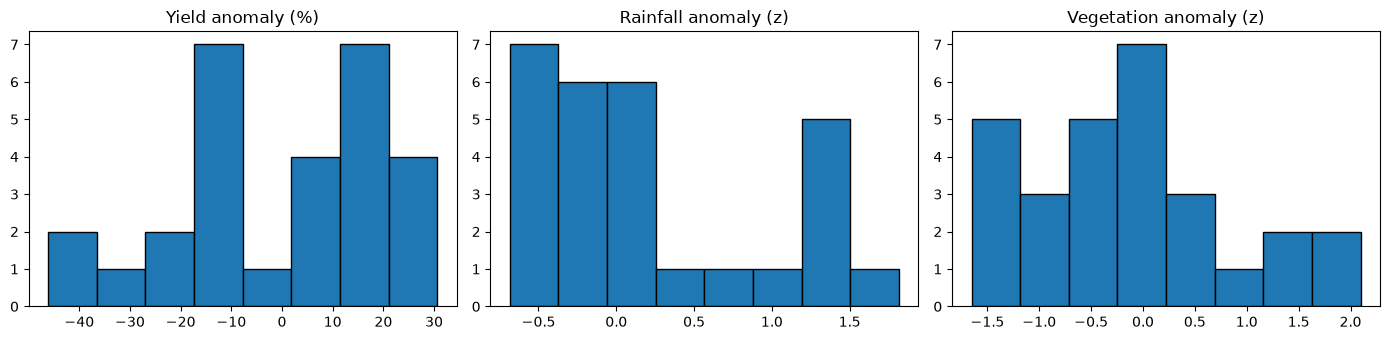

In [13]:
print('Missing values:', int(df.isna().sum().sum()))
print('\nSummary statistics:')
print(df[['yield_kg_ha', 'yield_anom', 'rain_mm', 'ndvi', 'rain_z', 'ndvi_z']].describe().round(2))

fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for ax, col, label in zip(axes, ['yield_anom', 'rain_z', 'ndvi_z'],
                          ['Yield anomaly (%)', 'Rainfall anomaly (z)', 'Vegetation anomaly (z)']):
    ax.hist(df[col], bins=8, edgecolor='black')
    ax.set_title(label)
plt.tight_layout(); plt.show()

### Relationships

rain_z vs yield anomaly: Pearson r = 0.60 (p = 0.001), Spearman rho = 0.66 (p = 0.000)
ndvi_z vs yield anomaly: Pearson r = 0.39 (p = 0.041), Spearman rho = 0.36 (p = 0.059)

Correlation between the two inputs: -0.17


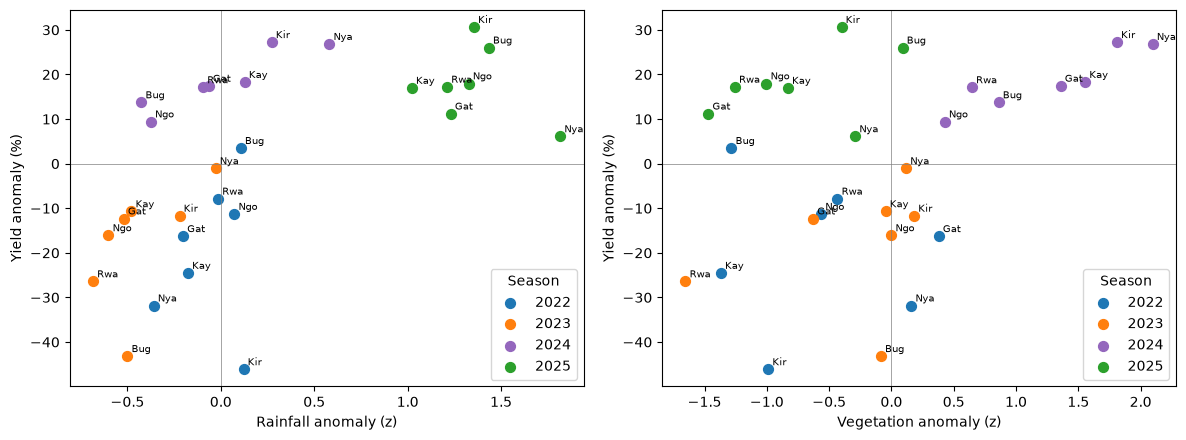

In [14]:
for feat in ['rain_z', 'ndvi_z']:
    r, p_r = stats.pearsonr(df[feat], df['yield_anom'])
    rho, p_s = stats.spearmanr(df[feat], df['yield_anom'])
    print(f'{feat} vs yield anomaly: Pearson r = {r:.2f} (p = {p_r:.3f}), Spearman rho = {rho:.2f} (p = {p_s:.3f})')
r_in, _ = stats.pearsonr(df['rain_z'], df['ndvi_z'])
print(f'\nCorrelation between the two inputs: {r_in:.2f}')

colors = dict(zip(YIELD_SEASONS, ['tab:blue', 'tab:orange', 'tab:purple', 'tab:green']))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, feat, label in zip(axes, ['rain_z', 'ndvi_z'], ['Rainfall anomaly (z)', 'Vegetation anomaly (z)']):
    for yr, g in df.groupby('season'):
        ax.scatter(g[feat], g['yield_anom'], color=colors[yr], label=str(yr), s=50)
        for _, row in g.iterrows():
            ax.annotate(row['district'][:3], (row[feat], row['yield_anom']), fontsize=7, xytext=(3, 3), textcoords='offset points')
    ax.axhline(0, lw=0.5, color='grey'); ax.axvline(0, lw=0.5, color='grey')
    ax.set_xlabel(label); ax.set_ylabel('Yield anomaly (%)'); ax.legend(title='Season')
plt.tight_layout(); plt.show()

In [15]:
for col in ['yield_anom', 'rain_z', 'ndvi_z']:
    z = (df[col] - df[col].mean()) / df[col].std(ddof=1)
    flagged = df.loc[z.abs() > 2, ['district', 'season', col]]
    print(f'{col}: {len(flagged)} point(s) beyond 2 standard deviations')
    if len(flagged):
        print(flagged.round(2).to_string(index=False))

yield_anom: 1 point(s) beyond 2 standard deviations
district  season  yield_anom
  Kirehe    2022      -46.14
rain_z: 1 point(s) beyond 2 standard deviations
 district  season  rain_z
Nyagatare    2025    1.82
ndvi_z: 1 point(s) beyond 2 standard deviations
 district  season  ndvi_z
Nyagatare    2024     2.1


### Correlation matrix

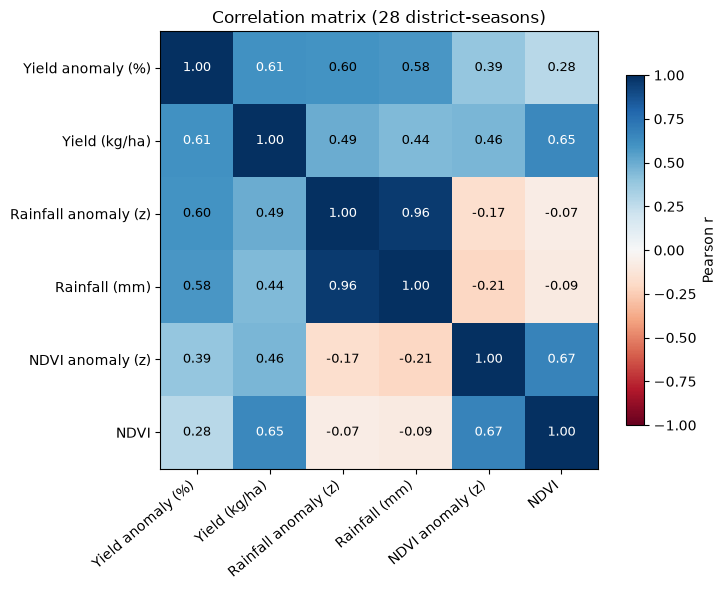

Rainfall anomaly vs yield anomaly: r = 0.60
NDVI anomaly vs yield anomaly:     r = 0.39
Rainfall vs NDVI anomaly:          r = -0.17 (low, so the inputs are not collinear)


In [16]:
# Correlation matrix of the modelling variables (Pearson)
cols = ['yield_anom', 'yield_kg_ha', 'rain_z', 'rain_mm', 'ndvi_z', 'ndvi']
labels = ['Yield anomaly (%)', 'Yield (kg/ha)', 'Rainfall anomaly (z)', 'Rainfall (mm)',
          'NDVI anomaly (z)', 'NDVI']
corr = df[cols].corr()

fig, ax = plt.subplots(figsize=(7.5, 6))
im = ax.imshow(corr, cmap='RdBu', vmin=-1, vmax=1)
ax.set_xticks(range(len(cols)), labels, rotation=40, ha='right')
ax.set_yticks(range(len(cols)), labels)
for i in range(len(cols)):
    for j in range(len(cols)):
        v = corr.iloc[i, j]
        ax.text(j, i, f'{v:.2f}', ha='center', va='center', fontsize=9,
                color='white' if abs(v) > 0.6 else 'black')
fig.colorbar(im, ax=ax, shrink=0.8, label='Pearson r')
ax.set_title(f'Correlation matrix ({len(df)} district-seasons)')
plt.tight_layout(); plt.show()

print(f"Rainfall anomaly vs yield anomaly: r = {corr.loc['rain_z', 'yield_anom']:.2f}")
print(f"NDVI anomaly vs yield anomaly:     r = {corr.loc['ndvi_z', 'yield_anom']:.2f}")
print(f"Rainfall vs NDVI anomaly:          r = {corr.loc['rain_z', 'ndvi_z']:.2f} (low, so the inputs are not collinear)")

### Yield by district and season

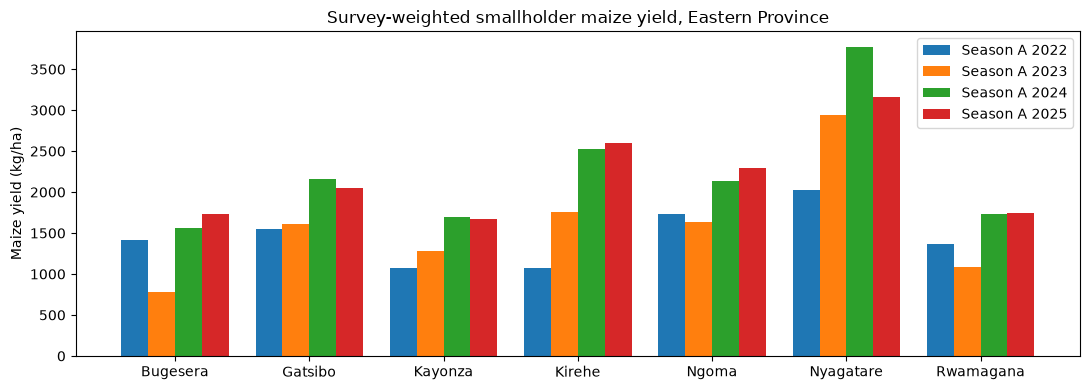

Province-wide mean yield by season (kg/ha):
season
2022    1462.0
2023    1585.0
2024    2227.0
2025    2177.0


In [17]:
# Maize yield by district and season: the target before it is turned into an anomaly
pivot = df.pivot(index='district', columns='season', values='yield_kg_ha')

fig, ax = plt.subplots(figsize=(11, 4))
width = 0.8 / len(pivot.columns)
for k, season in enumerate(pivot.columns):
    offset = (k - (len(pivot.columns) - 1) / 2) * width
    ax.bar(np.arange(len(pivot)) + offset, pivot[season], width, label=f'Season A {season}')
ax.set_xticks(range(len(pivot)), pivot.index)
ax.set_ylabel('Maize yield (kg/ha)')
ax.set_title('Survey-weighted smallholder maize yield, Eastern Province')
ax.legend()
plt.tight_layout(); plt.show()

print('Province-wide mean yield by season (kg/ha):')
print(pivot.mean().round(0).to_string())

### Seasonal patterns and cloud cover (EDA check 3)

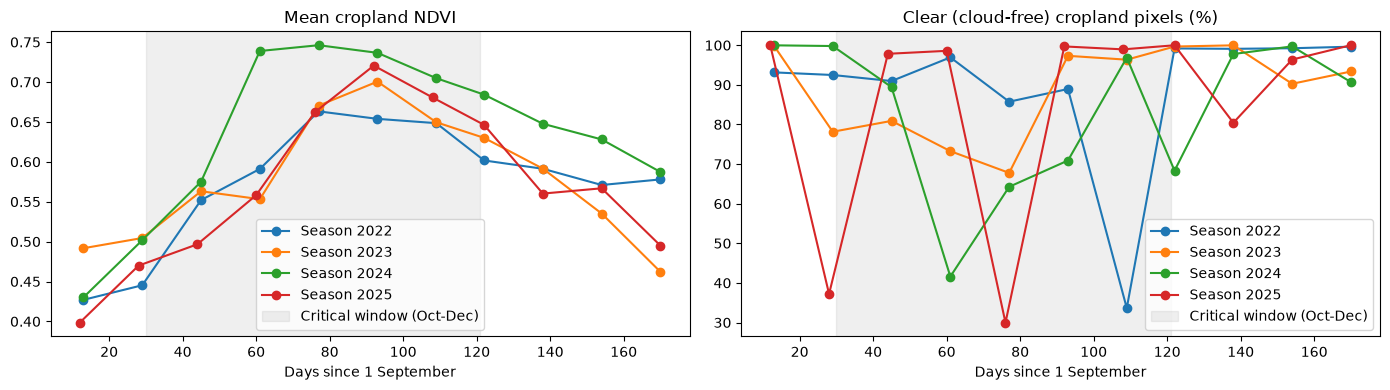

In [18]:
province = districts.union().geometry()

def season_profile(season_year):
    start = ee.Date.fromYMD(season_year - 1, 9, 1)
    end   = ee.Date.fromYMD(season_year, 3, 1)
    def one(img):
        valid = img.select('SummaryQA').lte(1)
        ndvi = img.select('NDVI').multiply(0.0001).updateMask(valid).updateMask(cropland)
        clear = valid.updateMask(cropland)
        stats_ = (ndvi.reduceRegion(ee.Reducer.mean(), province, 250, maxPixels=1e10)
                  .combine(clear.reduceRegion(ee.Reducer.mean(), province, 250, maxPixels=1e10)))
        return ee.Feature(None, {'date': img.date().format('YYYY-MM-dd'),
                                 'ndvi': stats_.get('NDVI'), 'clear_share': stats_.get('SummaryQA')})
    feats = ee.FeatureCollection(modis.filterDate(start, end).map(one)).getInfo()['features']
    return pd.DataFrame([f['properties'] for f in feats])

profiles = {y: season_profile(y) for y in YIELD_SEASONS}

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for y, p in profiles.items():
    day = (pd.to_datetime(p['date']) - pd.Timestamp(f'{y-1}-09-01')).dt.days
    axes[0].plot(day, p['ndvi'], marker='o', label=f'Season {y}')
    axes[1].plot(day, 100 * p['clear_share'], marker='o', label=f'Season {y}')
for ax, t in zip(axes, ['Mean cropland NDVI', 'Clear (cloud-free) cropland pixels (%)']):
    ax.axvspan(30, 121, alpha=0.12, color='grey', label='Critical window (Oct-Dec)')
    ax.set_title(t); ax.set_xlabel('Days since 1 September'); ax.legend()
plt.tight_layout(); plt.show()

### Sensitivity: peak NDVI
The proposal specifies mean NDVI over the critical window. The seasonal profiles show that 2025 greened later
but peaked higher than 2022 and 2023, which lowers its mean. Peak (maximum) NDVI, as used by Roznik et al. (2022),
is tested alongside mean NDVI. Mean NDVI remains the primary input.

In [19]:
def modis_peak_season(y):
    start, end = window(y)
    def clean(img):
        good = img.select('SummaryQA').lte(1)
        return img.select('NDVI').multiply(0.0001).updateMask(good)
    img = modis.filterDate(start, end).map(clean).max().rename('value')   # highest greenness in the window
    return img.updateMask(cropland).set('season', y)

if os.path.exists(PEAK_CSV):
    peak = pd.read_csv(PEAK_CSV)
    print('Loaded cached peak NDVI:', peak.shape)
else:
    peak = extract(modis_peak_season, MODIS_SEASONS, 250, 'ndvi_peak')
    peak.to_csv(PEAK_CSV, index=False)
    print('Extracted and saved:', peak.shape)

peak['ndvi_peak_z'] = peak.groupby('district')['ndvi_peak'].transform(zscore)
df = df.drop(columns=['ndvi_peak', 'ndvi_peak_z'], errors='ignore').merge(
        peak[['district', 'season', 'ndvi_peak', 'ndvi_peak_z']], on=['district', 'season'], how='left')

r, p = stats.pearsonr(df['ndvi_peak_z'], df['yield_anom'])
print(f'\nPeak NDVI vs yield anomaly: Pearson r = {r:.2f} (p = {p:.3f})')
r_mean, _ = stats.pearsonr(df['ndvi_z'], df['yield_anom'])
print(f'For comparison, mean NDVI: r = {r_mean:.2f}')
print(df.groupby('season')[['ndvi_z', 'ndvi_peak_z']].mean().round(2))

Loaded cached peak NDVI: (175, 3)

Peak NDVI vs yield anomaly: Pearson r = 0.58 (p = 0.001)
For comparison, mean NDVI: r = 0.39
        ndvi_z  ndvi_peak_z
season                     
2022     -0.59        -0.87
2023     -0.30        -0.15
2024      1.25         1.21
2025     -0.74         0.42


## 8. Model comparison
Models: Ridge, Lasso, quadratic OLS, and a mean-only baseline. Ridge and Lasso tune their penalty with an
inner leave-one-out loop on the training data only (nested cross-validation).
Validation: leave-one-out (as specified in the proposal) and leave-one-season-out (stricter: predicts an unseen year).
Main inputs: rain_z and ndvi_z (mean NDVI). Sensitivity: rain_z and ndvi_peak_z (peak NDVI).

In [20]:
from sklearn.model_selection import LeaveOneGroupOut

def add_squares(X):
    return np.hstack([X, X ** 2])

alphas = np.logspace(-3, 3, 50)
def make_models():
    return {
        'Baseline (mean)': DummyRegressor(strategy='mean'),
        'Ridge': Pipeline([('scale', StandardScaler()),
                           ('model', RidgeCV(alphas=alphas, cv=LeaveOneOut(), scoring='neg_mean_squared_error'))]),
        'Lasso': Pipeline([('scale', StandardScaler()),
                           ('model', LassoCV(alphas=alphas, cv=LeaveOneOut(), max_iter=50000))]),
        'Quadratic OLS': Pipeline([('squares', FunctionTransformer(add_squares)),
                                   ('model', LinearRegression())]),
    }

def evaluate(features):
    X = df[features].to_numpy(); y = df['yield_anom'].to_numpy()
    rows, preds = [], {}
    for scheme, cv in [('Leave-one-out', LeaveOneOut()), ('Leave-one-season-out', LeaveOneGroupOut())]:
        for name, model in make_models().items():
            p = cross_val_predict(model, X, y, cv=cv, groups=df['season'])
            preds[(scheme, name)] = p
            rows.append({'Validation': scheme, 'Model': name,
                         'RMSE': np.sqrt(mean_squared_error(y, p)),
                         'MAE': mean_absolute_error(y, p),
                         'Predictive R2': 1 - np.sum((y - p) ** 2) / np.sum((y - y.mean()) ** 2)})
    return pd.DataFrame(rows).set_index(['Validation', 'Model']).round(2), preds

results_main, preds_main = evaluate(['rain_z', 'ndvi_z'])
results_peak, preds_peak = evaluate(['rain_z', 'ndvi_peak_z'])

print('MAIN: rainfall + mean NDVI')
print(results_main)
print('\nSENSITIVITY: rainfall + peak NDVI')
print(results_peak)

/private/tmp/claude-501/-Users-apple-Desktop-parametric-drought-simulator/888c1cf9-2877-4e45-b127-cd47dc9a227f/scratchpad/nbenv/lib/python3.12/site-packages/sklearn/model_selection/_split.py:86: UserWarning: The groups parameter is ignored by LeaveOneOut
  warnings.warn(
/private/tmp/claude-501/-Users-apple-Desktop-parametric-drought-simulator/888c1cf9-2877-4e45-b127-cd47dc9a227f/scratchpad/nbenv/lib/python3.12/site-packages/sklearn/model_selection/_split.py:86: UserWarning: The groups parameter is ignored by LeaveOneOut
  warnings.warn(


/private/tmp/claude-501/-Users-apple-Desktop-parametric-drought-simulator/888c1cf9-2877-4e45-b127-cd47dc9a227f/scratchpad/nbenv/lib/python3.12/site-packages/sklearn/model_selection/_split.py:86: UserWarning: The groups parameter is ignored by LeaveOneOut
  warnings.warn(


/private/tmp/claude-501/-Users-apple-Desktop-parametric-drought-simulator/888c1cf9-2877-4e45-b127-cd47dc9a227f/scratchpad/nbenv/lib/python3.12/site-packages/sklearn/model_selection/_split.py:86: UserWarning: The groups parameter is ignored by LeaveOneOut
  warnings.warn(


/private/tmp/claude-501/-Users-apple-Desktop-parametric-drought-simulator/888c1cf9-2877-4e45-b127-cd47dc9a227f/scratchpad/nbenv/lib/python3.12/site-packages/sklearn/model_selection/_split.py:86: UserWarning: The groups parameter is ignored by LeaveOneOut
  warnings.warn(
/private/tmp/claude-501/-Users-apple-Desktop-parametric-drought-simulator/888c1cf9-2877-4e45-b127-cd47dc9a227f/scratchpad/nbenv/lib/python3.12/site-packages/sklearn/model_selection/_split.py:86: UserWarning: The groups parameter is ignored by LeaveOneOut
  warnings.warn(


/private/tmp/claude-501/-Users-apple-Desktop-parametric-drought-simulator/888c1cf9-2877-4e45-b127-cd47dc9a227f/scratchpad/nbenv/lib/python3.12/site-packages/sklearn/model_selection/_split.py:86: UserWarning: The groups parameter is ignored by LeaveOneOut
  warnings.warn(


/private/tmp/claude-501/-Users-apple-Desktop-parametric-drought-simulator/888c1cf9-2877-4e45-b127-cd47dc9a227f/scratchpad/nbenv/lib/python3.12/site-packages/sklearn/model_selection/_split.py:86: UserWarning: The groups parameter is ignored by LeaveOneOut
  warnings.warn(


MAIN: rainfall + mean NDVI
                                       RMSE    MAE  Predictive R2
Validation           Model                                       
Leave-one-out        Baseline (mean)  22.16  19.22          -0.08
                     Ridge            14.95  11.38           0.51
                     Lasso            14.92  11.32           0.51
                     Quadratic OLS    16.53  12.52           0.40
Leave-one-season-out Baseline (mean)  26.78  24.39          -0.57
                     Ridge            19.91  16.74           0.13
                     Lasso            21.31  18.06           0.01
                     Quadratic OLS    63.10  41.53          -7.72

SENSITIVITY: rainfall + peak NDVI
                                       RMSE    MAE  Predictive R2
Validation           Model                                       
Leave-one-out        Baseline (mean)  22.16  19.22          -0.08
                     Ridge            15.77  11.52           0.46
              

### Selected model
Ridge regression on `rain_z` and `ndvi_z`. Under leave-one-out, Ridge and Lasso are effectively tied
(RMSE 14.95 against 14.92, both predictive R² 0.51). Under the stricter leave-one-season-out test, which
predicts a whole unseen year, Ridge is clearly better (R² 0.13 against 0.01) and is the only model that explains
a meaningful share of an unseen year, so it is selected. Both beat the mean-only baseline. With four seasons,
every model is still much weaker on an unseen year than on an unseen district-season, a limitation reported
in the results.

In [21]:
FEATURES = ['rain_z', 'ndvi_z']
X = df[FEATURES].to_numpy(); y = df['yield_anom'].to_numpy()

best = make_models()['Ridge'].fit(X, y)
ridge = best.named_steps['model']
print(f'Selected penalty strength (alpha): {ridge.alpha_:.3f}')
print('Coefficients (per 1 standard deviation of each input):')
for f, c in zip(FEATURES, ridge.coef_):
    print(f'  {f}: {c:+.2f} percentage points of yield')
print(f'  intercept: {ridge.intercept_:+.2f}')

df['index_loo'] = preds_main[('Leave-one-out', 'Ridge')]
results_main.to_csv(f'{DATA_DIR}/model_results_main.csv')
results_peak.to_csv(f'{DATA_DIR}/model_results_peak.csv')
print('\nResults tables saved to', DATA_DIR.name)

Selected penalty strength (alpha): 2.024
Coefficients (per 1 standard deviation of each input):
  rain_z: +13.47 percentage points of yield
  ndvi_z: +9.91 percentage points of yield
  intercept: -0.00

Results tables saved to data


### Model architecture

The selected model is a regularised linear regression, chosen because so few observations cannot support
a model with many free parameters (proposal §3.9). It has no hidden layers or activation functions.

```
rain_z ─┐
        ├─► StandardScaler ─► Ridge regression ─► predicted yield change ─► payout rule
ndvi_z ─┘   (mean 0, sd 1)    (linear, L2 penalty)  (the drought index, %)    (0 above the trigger,
                                                                              rising to 100% at the exit)
```

| Component | Choice |
|---|---|
| Inputs | 2 features: rainfall anomaly `rain_z`, vegetation anomaly `ndvi_z` |
| Preprocessing | `StandardScaler`, so the penalty treats both inputs equally |
| Model | `index = b0 + b1·rain + b2·ndvi` (standardised inputs) |
| Loss | squared error + α·(b1² + b2²) (Ridge / L2 penalty) |
| Optimisation | closed-form least-squares solution (no gradient descent or epochs needed) |
| Hyperparameter | α chosen from 50 values between 0.001 and 1000 by leave-one-out cross-validation on the training rows only (nested inside the outer validation) |
| Output | predicted yield anomaly (%), which is the drought index |
| Decision layer | trigger and exit, chosen in Section 9 |

The cell below shows the fitted pipeline, the learned weights, and how the validation error changes
with α.

Pipeline: scale (StandardScaler) -> model (RidgeCV)
Scaler mean: [ 0.212 -0.094], scale: [0.716 0.983]
index = 0.00 +13.47 x rain (standardised) +9.91 x ndvi (standardised)
Selected alpha: 2.024


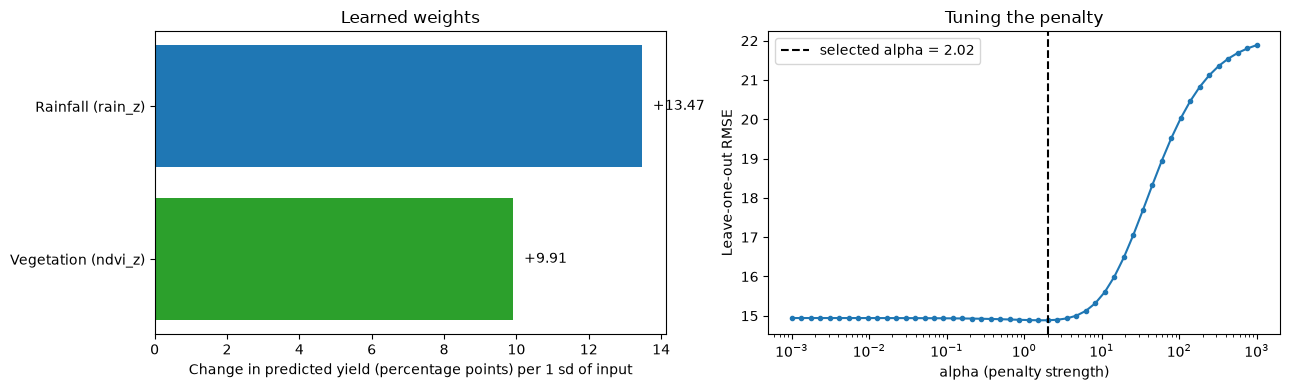

Rainfall carries 58% of the model weight, vegetation 42%.


In [22]:
print('Pipeline:', ' -> '.join(f'{name} ({type(step).__name__})' for name, step in best.steps))
print(f'Scaler mean: {best.named_steps["scale"].mean_.round(3)}, scale: {best.named_steps["scale"].scale_.round(3)}')
b0, (b1, b2) = round(ridge.intercept_, 2) + 0.0, ridge.coef_
print(f'index = {b0:.2f} {b1:+.2f} x rain (standardised) {b2:+.2f} x ndvi (standardised)')
print(f'Selected alpha: {ridge.alpha_:.3f}')

# Validation error for each alpha (leave-one-out, same folds as the tuning)
from sklearn.linear_model import Ridge
curve = []
for a in alphas:
    p = cross_val_predict(Pipeline([('scale', StandardScaler()), ('model', Ridge(alpha=a))]),
                          X, y, cv=LeaveOneOut())
    curve.append(np.sqrt(mean_squared_error(y, p)))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].barh(['Vegetation (ndvi_z)', 'Rainfall (rain_z)'], [b2, b1], color=['tab:green', 'tab:blue'])
for v, ypos in zip([b2, b1], [0, 1]):
    axes[0].text(v + 0.3, ypos, f'{v:+.2f}', va='center')
axes[0].set_xlabel('Change in predicted yield (percentage points) per 1 sd of input')
axes[0].set_title('Learned weights')

axes[1].semilogx(alphas, curve, marker='.')
axes[1].axvline(ridge.alpha_, ls='--', color='black', label=f'selected alpha = {ridge.alpha_:.2f}')
axes[1].set_xlabel('alpha (penalty strength)'); axes[1].set_ylabel('Leave-one-out RMSE')
axes[1].set_title('Tuning the penalty'); axes[1].legend()
plt.tight_layout(); plt.show()

share = abs(b1) / (abs(b1) + abs(b2))
print(f'Rainfall carries {share:.0%} of the model weight, vegetation {1 - share:.0%}.')

## 9. Payout trigger, exit, and basis risk
Index = the selected model's predicted yield anomaly (leave-one-out predictions, so thresholds are not fitted to the same data).
Payouts start at the trigger and rise linearly to the exit. A low-yield season is one at least 10% below the district average.

In [23]:
index = df['index_loo'].to_numpy()
low = df['yield_anom'].to_numpy() <= LOW_YIELD_THRESHOLD
print(f'Low-yield district-seasons: {low.sum()} of {len(df)}\n')

scan = []
for t in np.arange(-1, -31, -1):
    pays = index <= t
    scan.append({'trigger': t,
                 'hit_rate': pays[low].mean(),
                 'false_payout_rate': pays[~low].mean()})
scan = pd.DataFrame(scan)
scan['score'] = scan['hit_rate'] - scan['false_payout_rate']
TRIGGER = float(scan.loc[scan['score'].idxmax(), 'trigger'])
EXIT = TRIGGER - 20.0
best_row = scan.loc[scan['trigger'] == TRIGGER].iloc[0]
print(f'Trigger: {TRIGGER:.0f}% | Exit: {EXIT:.0f}%')
print(f'Hit rate: {best_row.hit_rate:.0%} | False payout rate: {best_row.false_payout_rate:.0%}')

def payout_fraction(v):
    return np.clip((TRIGGER - v) / (TRIGGER - EXIT), 0, 1)

df['payout'] = payout_fraction(df['index_loo'])
df['payout_if_actual'] = payout_fraction(df['yield_anom'])
df['basis_risk'] = (df['payout'] - df['payout_if_actual']).abs()

print('\nBasis risk per district (0 = index pays exactly what the loss justifies, 1 = completely wrong):')
print(df.groupby('district')['basis_risk'].mean().round(2).sort_values(ascending=False).to_string())

print('\nSeason by season:')
print(df[['district', 'season', 'yield_anom', 'index_loo', 'payout', 'payout_if_actual']].round(2).to_string(index=False))

Low-yield district-seasons: 11 of 28

Trigger: -4% | Exit: -24%
Hit rate: 91% | False payout rate: 18%

Basis risk per district (0 = index pays exactly what the loss justifies, 1 = completely wrong):
district
Bugesera     0.31
Kirehe       0.28
Gatsibo      0.25
Nyagatare    0.22
Ngoma        0.11
Kayonza      0.08
Rwamagana    0.00

Season by season:
 district  season  yield_anom  index_loo  payout  payout_if_actual
 Bugesera    2022        3.47     -15.67    0.58              0.00
  Gatsibo    2022      -16.29      -2.30    0.00              0.61
  Kayonza    2022      -24.53     -19.61    0.78              1.00
   Kirehe    2022      -46.14      -8.43    0.22              1.00
    Ngoma    2022      -11.30      -7.16    0.16              0.37
Nyagatare    2022      -31.84      -6.75    0.14              1.00
Rwamagana    2022       -7.88      -7.66    0.18              0.19
 Bugesera    2023      -43.19     -11.07    0.35              1.00
  Gatsibo    2023      -12.33     -19.79   

### Trigger selection
Every whole-number trigger from -1% to -30% is scored by hit rate minus false payout rate on the
leave-one-out index, and the best-scoring trigger is kept (the first, if several tie). The chart and
the table below show the trade-off: an earlier trigger pays in more poor seasons but makes more false payouts.

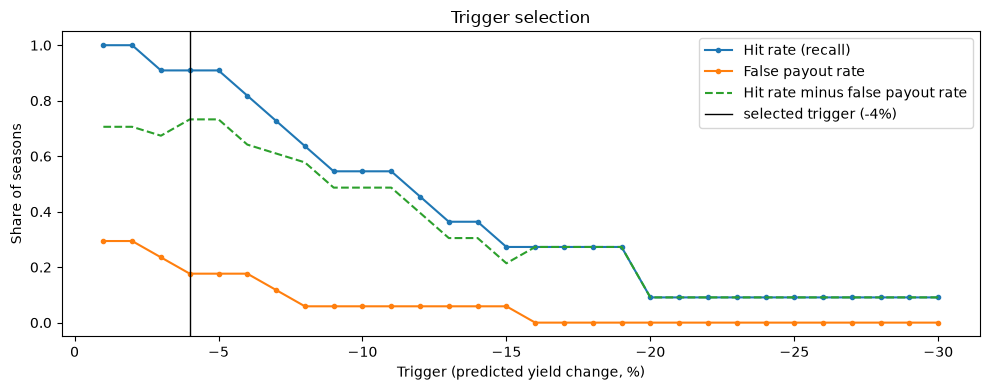

Best-scoring trigger(s):
 trigger hit_rate false_payout_rate  score
      -4      91%               18%   0.73
      -5      91%               18%   0.73


In [24]:
# How the trigger was chosen: hit rate against false payout rate for every candidate trigger
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(scan['trigger'], scan['hit_rate'], marker='.', label='Hit rate (recall)')
ax.plot(scan['trigger'], scan['false_payout_rate'], marker='.', label='False payout rate')
ax.plot(scan['trigger'], scan['score'], ls='--', label='Hit rate minus false payout rate')
ax.axvline(TRIGGER, color='black', lw=1, label=f'selected trigger ({TRIGGER:.0f}%)')
ax.set_xlabel('Trigger (predicted yield change, %)'); ax.set_ylabel('Share of seasons')
ax.invert_xaxis(); ax.legend(); ax.set_title('Trigger selection')
plt.tight_layout(); plt.show()

top = scan[scan['score'] == scan['score'].max()]
print('Best-scoring trigger(s):')
print(top.assign(hit_rate=top['hit_rate'].map('{:.0%}'.format),
                 false_payout_rate=top['false_payout_rate'].map('{:.0%}'.format),
                 score=top['score'].round(2)).to_string(index=False))

### Initial performance metrics of the selected model

Two views of performance, both on leave-one-out predictions (each district-season predicted by a model
that never saw it):

1. **Regression:** how close the predicted yield change is to the actual one (RMSE, MAE, predictive R²,
   reported in Section 8).
2. **Classification:** the insurance decision. A season is a true *poor season* when the actual yield is
   at least 10% below the district average; the index *pays* when its prediction is at or below the
   trigger. This gives accuracy, precision, recall (the hit rate) and F1.

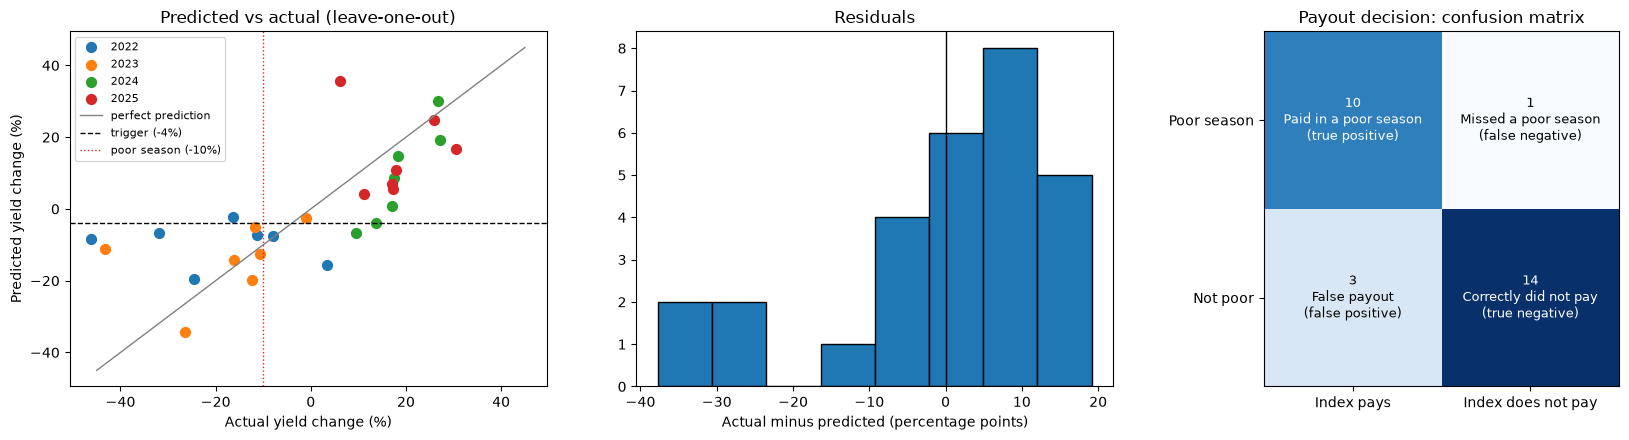

           Metric Value                                                           Meaning
         Accuracy   86% share of the 28 seasons where the pay / no-pay decision was right
        Precision   77%        of the seasons the index paid, share that were really poor
Recall (hit rate)   91%                         of the poor seasons, share the index paid
         F1-score   83%                                   balance of precision and recall
      Specificity   82%      of the normal seasons, share the index correctly did not pay
False payout rate   18%     of the normal seasons, share the index paid (1 - specificity)

Regression (leave-one-out): RMSE 14.95, MAE 11.38, predictive R2 0.51


In [25]:
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score,
                             precision_score, recall_score)

# 1. Regression view
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
ax = axes[0]
for yr, g in df.groupby('season'):
    ax.scatter(g['yield_anom'], g['index_loo'], s=50, label=str(yr))
lim = [-45, 45]
ax.plot(lim, lim, color='grey', lw=1, label='perfect prediction')
ax.axhline(TRIGGER, ls='--', color='black', lw=1, label=f'trigger ({TRIGGER:.0f}%)')
ax.axvline(LOW_YIELD_THRESHOLD, ls=':', color='tab:red', lw=1, label='poor season (-10%)')
ax.set_xlabel('Actual yield change (%)'); ax.set_ylabel('Predicted yield change (%)')
ax.set_title('Predicted vs actual (leave-one-out)'); ax.legend(fontsize=8)

resid = df['yield_anom'] - df['index_loo']
axes[1].hist(resid, bins=8, edgecolor='black')
axes[1].axvline(0, color='black', lw=1)
axes[1].set_xlabel('Actual minus predicted (percentage points)'); axes[1].set_title('Residuals')

# 2. Classification view: the payout decision
actual_poor = df['yield_anom'] <= LOW_YIELD_THRESHOLD
index_pays = df['index_loo'] <= TRIGGER
cm = confusion_matrix(actual_poor, index_pays, labels=[True, False])
ax = axes[2]
ax.imshow(cm, cmap='Blues')
names = [['Paid in a poor season\n(true positive)', 'Missed a poor season\n(false negative)'],
         ['False payout\n(false positive)', 'Correctly did not pay\n(true negative)']]
for i in range(2):
    for j in range(2):
        ax.text(j, i, f'{cm[i, j]}\n{names[i][j]}', ha='center', va='center', fontsize=9,
                color='white' if cm[i, j] > cm.max() / 2 else 'black')
ax.set_xticks([0, 1], ['Index pays', 'Index does not pay'])
ax.set_yticks([0, 1], ['Poor season', 'Not poor'])
ax.set_title('Payout decision: confusion matrix')
plt.tight_layout(); plt.show()

tn = cm[1, 1]; fp = cm[1, 0]
metrics = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall (hit rate)', 'F1-score',
               'Specificity', 'False payout rate'],
    'Value': [accuracy_score(actual_poor, index_pays), precision_score(actual_poor, index_pays),
              recall_score(actual_poor, index_pays), f1_score(actual_poor, index_pays),
              tn / (tn + fp), fp / (tn + fp)],
    'Meaning': [f'share of the {len(df)} seasons where the pay / no-pay decision was right',
                'of the seasons the index paid, share that were really poor',
                'of the poor seasons, share the index paid',
                'balance of precision and recall',
                'of the normal seasons, share the index correctly did not pay',
                'of the normal seasons, share the index paid (1 - specificity)'],
})
metrics['Value'] = metrics['Value'].map('{:.0%}'.format)
print(metrics.to_string(index=False))

reg = results_main.loc[('Leave-one-out', 'Ridge')]
print(f"\nRegression (leave-one-out): RMSE {reg['RMSE']:.2f}, MAE {reg['MAE']:.2f}, "
      f"predictive R2 {reg['Predictive R2']:.2f}")

## 10. Check against documented drought years
The selected model is applied to satellite data for every season since 2001 (not used in training).
Niyonsenga et al. (2024) identify 2003-2006 and 2013-2017 as Rwanda's most severe drought years.
Seasons are compared by the calendar year of their critical window (Season Y's window falls in Y-1).

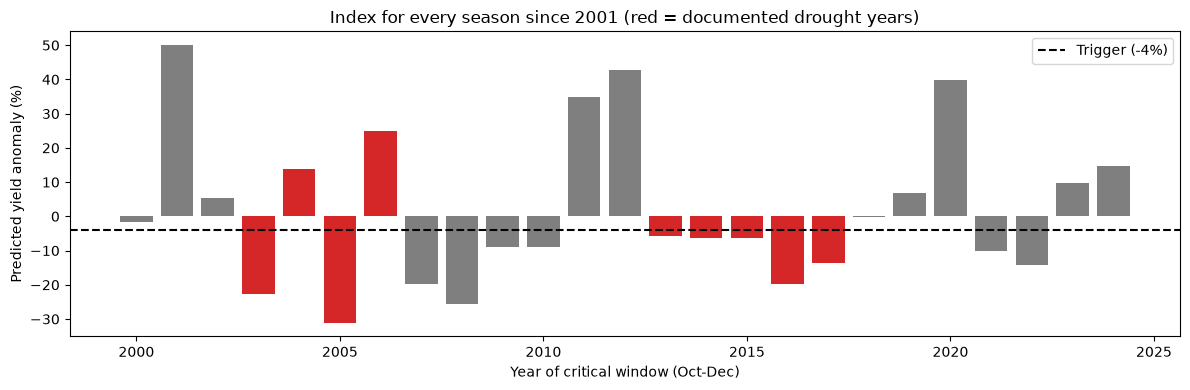

Documented drought years: payout in 68% of district-seasons (43 of 63)
Other years: payout in 38% of district-seasons (43 of 112)

By year:
             index  districts_paid  drought
window_year                                
2000          -1.6               3    False
2001          50.0               0    False
2002           5.3               1    False
2003         -22.6               7     True
2004          13.9               1     True
2005         -31.1               7     True
2006          24.8               0     True
2007         -19.8               7    False
2008         -25.6               7    False
2009          -8.9               5    False
2010          -8.9               5    False
2011          34.9               0    False
2012          42.6               0    False
2013          -5.9               5     True
2014          -6.5               5     True
2015          -6.3               5     True
2016         -19.8               7     True
2017         -13.5      

In [26]:
hist = sat.dropna(subset=FEATURES).copy()
hist['index'] = best.predict(hist[FEATURES].to_numpy())
hist['window_year'] = hist['season'] - 1
hist['pays'] = hist['index'] <= TRIGGER
hist['drought_year'] = hist['window_year'].isin(DROUGHT_YEARS)

by_year = hist.groupby('window_year').agg(index=('index', 'mean'), districts_paid=('pays', 'sum'))

plt.figure(figsize=(12, 4))
plt.bar(by_year.index, by_year['index'],
        color=['tab:red' if y in DROUGHT_YEARS else 'tab:grey' for y in by_year.index])
plt.axhline(TRIGGER, ls='--', color='black', label=f'Trigger ({TRIGGER:.0f}%)')
plt.xlabel('Year of critical window (Oct-Dec)'); plt.ylabel('Predicted yield anomaly (%)')
plt.title('Index for every season since 2001 (red = documented drought years)')
plt.legend(); plt.tight_layout(); plt.show()

for label, g in [('Documented drought years', hist[hist['drought_year']]),
                 ('Other years', hist[~hist['drought_year']])]:
    print(f'{label}: payout in {g["pays"].mean():.0%} of district-seasons ({g["pays"].sum()} of {len(g)})')

print('\nBy year:')
print(by_year.assign(drought=by_year.index.isin(DROUGHT_YEARS)).round(1).to_string())

## 11. Export for the backend
Saves the model (coefficients, scaler, thresholds), the calibration district-seasons, and the index for every
district-season since 1982, straight into `backend/data/`. A final check confirms the exported numbers reproduce the fitted model.

In [27]:
os.makedirs(EXPORT_DIR, exist_ok=True)

scaler = best.named_steps['scale']

# 1. Model and summary numbers
model_export = {
    'model': 'Ridge',
    'features': FEATURES,
    'scaler_mean': scaler.mean_.tolist(),
    'scaler_scale': scaler.scale_.tolist(),
    'coefficients': ridge.coef_.tolist(),
    'intercept': float(ridge.intercept_),
    'alpha': float(ridge.alpha_),
    'trigger': TRIGGER,
    'exit': EXIT,
    'low_yield_threshold': LOW_YIELD_THRESHOLD,
    'hit_rate': float(best_row.hit_rate),
    'false_payout_rate': float(best_row.false_payout_rate),
    'window_months': [WIN_START_MONTH, WIN_END_MONTH],
    'drought_years': DROUGHT_YEARS,
    'validation_main': results_main.reset_index().to_dict(orient='records'),
    'validation_peak_ndvi': results_peak.reset_index().to_dict(orient='records'),
}
with open(f'{EXPORT_DIR}/model.json', 'w') as f:
    json.dump(model_export, f, indent=2)

# 2. The calibration district-seasons
calib = df[['district', 'season', 'yield_kg_ha', 'yield_anom', 'rain_z', 'ndvi_z',
            'index_loo', 'payout', 'payout_if_actual', 'basis_risk']].round(4)
calib.to_csv(f'{EXPORT_DIR}/calibration.csv', index=False)

# 3. Every district-season since 1982
seasons_out = sat[['district', 'season', 'rain_mm', 'ndvi', 'rain_z', 'ndvi_z']].copy()
has_both = seasons_out['ndvi_z'].notna()
seasons_out.loc[has_both, 'index'] = best.predict(seasons_out.loc[has_both, FEATURES].to_numpy())
seasons_out['payout'] = payout_fraction(seasons_out['index'])
seasons_out['window_year'] = seasons_out['season'] - 1
seasons_out['drought_year'] = seasons_out['window_year'].isin(DROUGHT_YEARS)
seasons_out.round(4).to_csv(f'{EXPORT_DIR}/seasons.csv', index=False)

# Check: the saved numbers alone reproduce the model's predictions
m = model_export
Xs = (df[FEATURES].to_numpy() - np.array(m['scaler_mean'])) / np.array(m['scaler_scale'])
manual = Xs @ np.array(m['coefficients']) + m['intercept']
assert np.allclose(manual, best.predict(df[FEATURES].to_numpy())), 'Export does not reproduce the model'

print('Export check passed: saved coefficients reproduce the model exactly\n')
for fn in ['model.json', 'calibration.csv', 'seasons.csv']:
    print(f'{fn}: {os.path.getsize(f"{EXPORT_DIR}/{fn}") / 1024:.1f} KB')
print(f'\nseasons.csv: {len(seasons_out)} rows, {seasons_out["index"].notna().sum()} with an index (2001 onward)')

Export check passed: saved coefficients reproduce the model exactly

model.json: 3.1 KB
calibration.csv: 2.0 KB
seasons.csv: 17.5 KB

seasons.csv: 308 rows, 175 with an index (2001 onward)


## 12. Deployment option: web dashboard and API

The exported model (Section 11) is served by a working MVP in the project repository
(https://github.com/JokMaker/parametric-drought-simulator):

- **API (FastAPI):** loads `model.json`, `calibration.csv` and `seasons.csv`, applies the saved scaler
  and coefficients, and serves `/api/model`, `/api/simulate`, `/api/history`, `/api/basis-risk` and
  `/api/seasons`. Interactive **Swagger UI** at `http://localhost:8000/docs`.
- **Dashboard (Next.js):** Overview, District Explorer (payout and the reason for it), Drought History
  and Basis Risk.
- **Run:** `docker compose up --build` from the repository root, then open `http://localhost:3000`.
- **Checks:** backend tests confirm the API reproduces this notebook's results (index formula on all
  175 district-seasons, hit and false payout rates, drought-year totals, basis risk).

**Swagger UI**

![API documentation](https://raw.githubusercontent.com/JokMaker/parametric-drought-simulator/main/docs/screenshots/api-docs.png)

**District Explorer: Rwamagana, Season A 2023**

![District Explorer](https://raw.githubusercontent.com/JokMaker/parametric-drought-simulator/main/docs/screenshots/explorer-rwamagana-2023.png)

**Drought History**

![Drought History](https://raw.githubusercontent.com/JokMaker/parametric-drought-simulator/main/docs/screenshots/drought-history.png)